In [1]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = os.path.join(os.pardir)
sys.path.append(os.path.join(project_folder, 'analysis-suite'))
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', 'opticflow')

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *


In [3]:
N = 93
K = 10

V_width = 1
V_E_buffer_array = np.arange(20).astype(int)
E_width = 1

In [4]:
sweep_dims = (len(V_E_buffer_array),)
bank_data = np.zeros(sweep_dims, dtype=object)
basis_neurons = np.zeros(sweep_dims, dtype=object)

for i, V_E_buffer in enumerate(V_E_buffer_array):
    load_path = os.path.join(bank_directory, f'({V_width},{V_E_buffer},{E_width}) K={K}.dat')
    with open(load_path, 'rb') as f:
        data_dict = pickle.load(f)
    basis_neurons[i] = data_dict["basis_vectors"]
    bank_data[i] = data_dict

mov_name = data_dict["mov_name"]

In [5]:
ref = basis_neurons[0]
for i in range(len(V_E_buffer_array)):
    for k in range(K):
        cur_leading = basis_neurons[i][:,k]
        cur_sign = np.sign(ref[:,k] @ cur_leading)
        basis_neurons[i][:,k] *= cur_sign

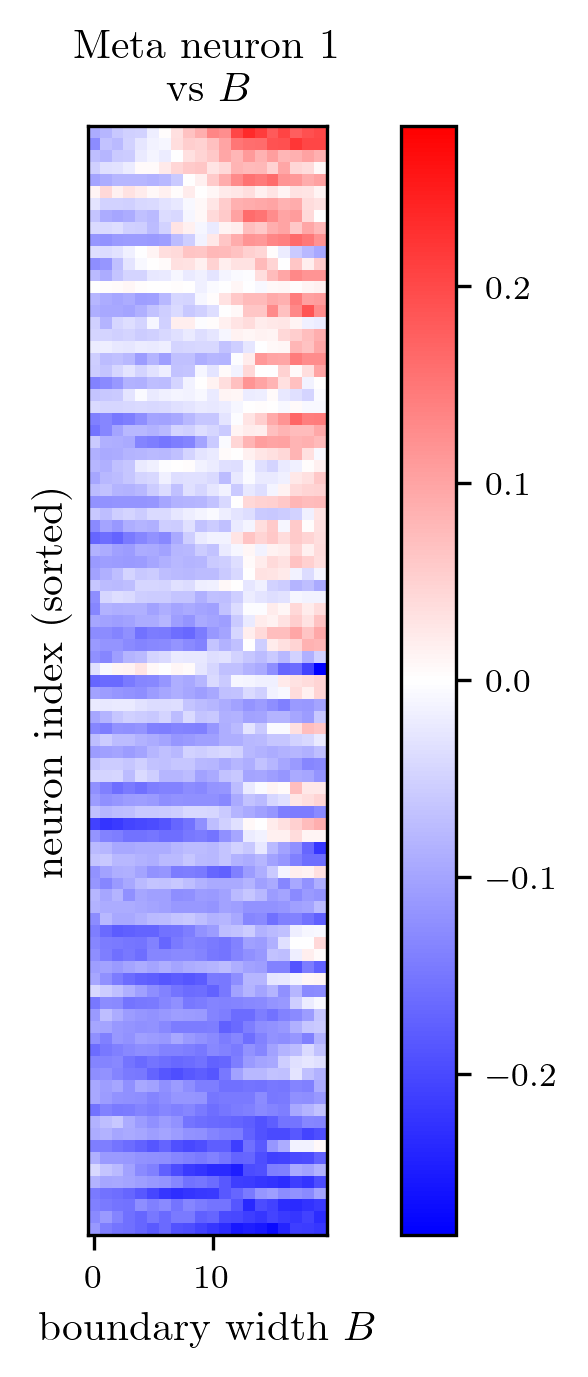

In [6]:
mode_index = 0
viewing_dims = (V_width, N)
modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]

plt.figure(dpi=300)
stacked = np.concatenate(modes, axis=1)
# sort_inds = np.argsort(np.sum(np.arange(V_width)[None,:]*stacked, axis=1))
sort_inds = np.argsort(np.sum(stacked, axis=1))
mx = np.amax(np.abs(stacked))
x = V_E_buffer_array
y = np.arange(N)
plt.pcolor(x, y, stacked[sort_inds], cmap='bwr', vmin=-mx, vmax=mx)
plt.title(f'Meta neuron {mode_index+1}\n vs $B$')
plt.xlabel('boundary width $B$')
plt.ylabel('neuron index (sorted)')
ax = plt.gca()
ax.set_yticks([])
ax.set_aspect('equal')
plt.colorbar()

# Multiple

In [7]:
def single_mode_plot(ax, mode_index):
    viewing_dims = (V_width, N)
    modes = [a[:,mode_index].T.reshape(viewing_dims).T for a in basis_neurons]
    stacked = np.concatenate(modes, axis=1)
    # sort_inds = np.argsort(np.sum(np.arange(V_width)[None,:]*stacked, axis=1))
    sort_inds = np.argsort(np.sum(stacked, axis=1))
    mx = np.amax(np.abs(stacked))
    x = V_E_buffer_array
    y = np.arange(N)
    ax.pcolor(x, y, stacked[sort_inds], cmap='bwr', vmin=-mx, vmax=mx)
    ax.set_title(f'Meta neuron {mode_index+1}\n vs $B$')
    ax.set_xlabel('boundary $B$')
    if n == 0:
        ax.set_ylabel('neuron index (sorted)')
    ax.set_yticks([])
    ax.set_aspect('equal')
    return ax

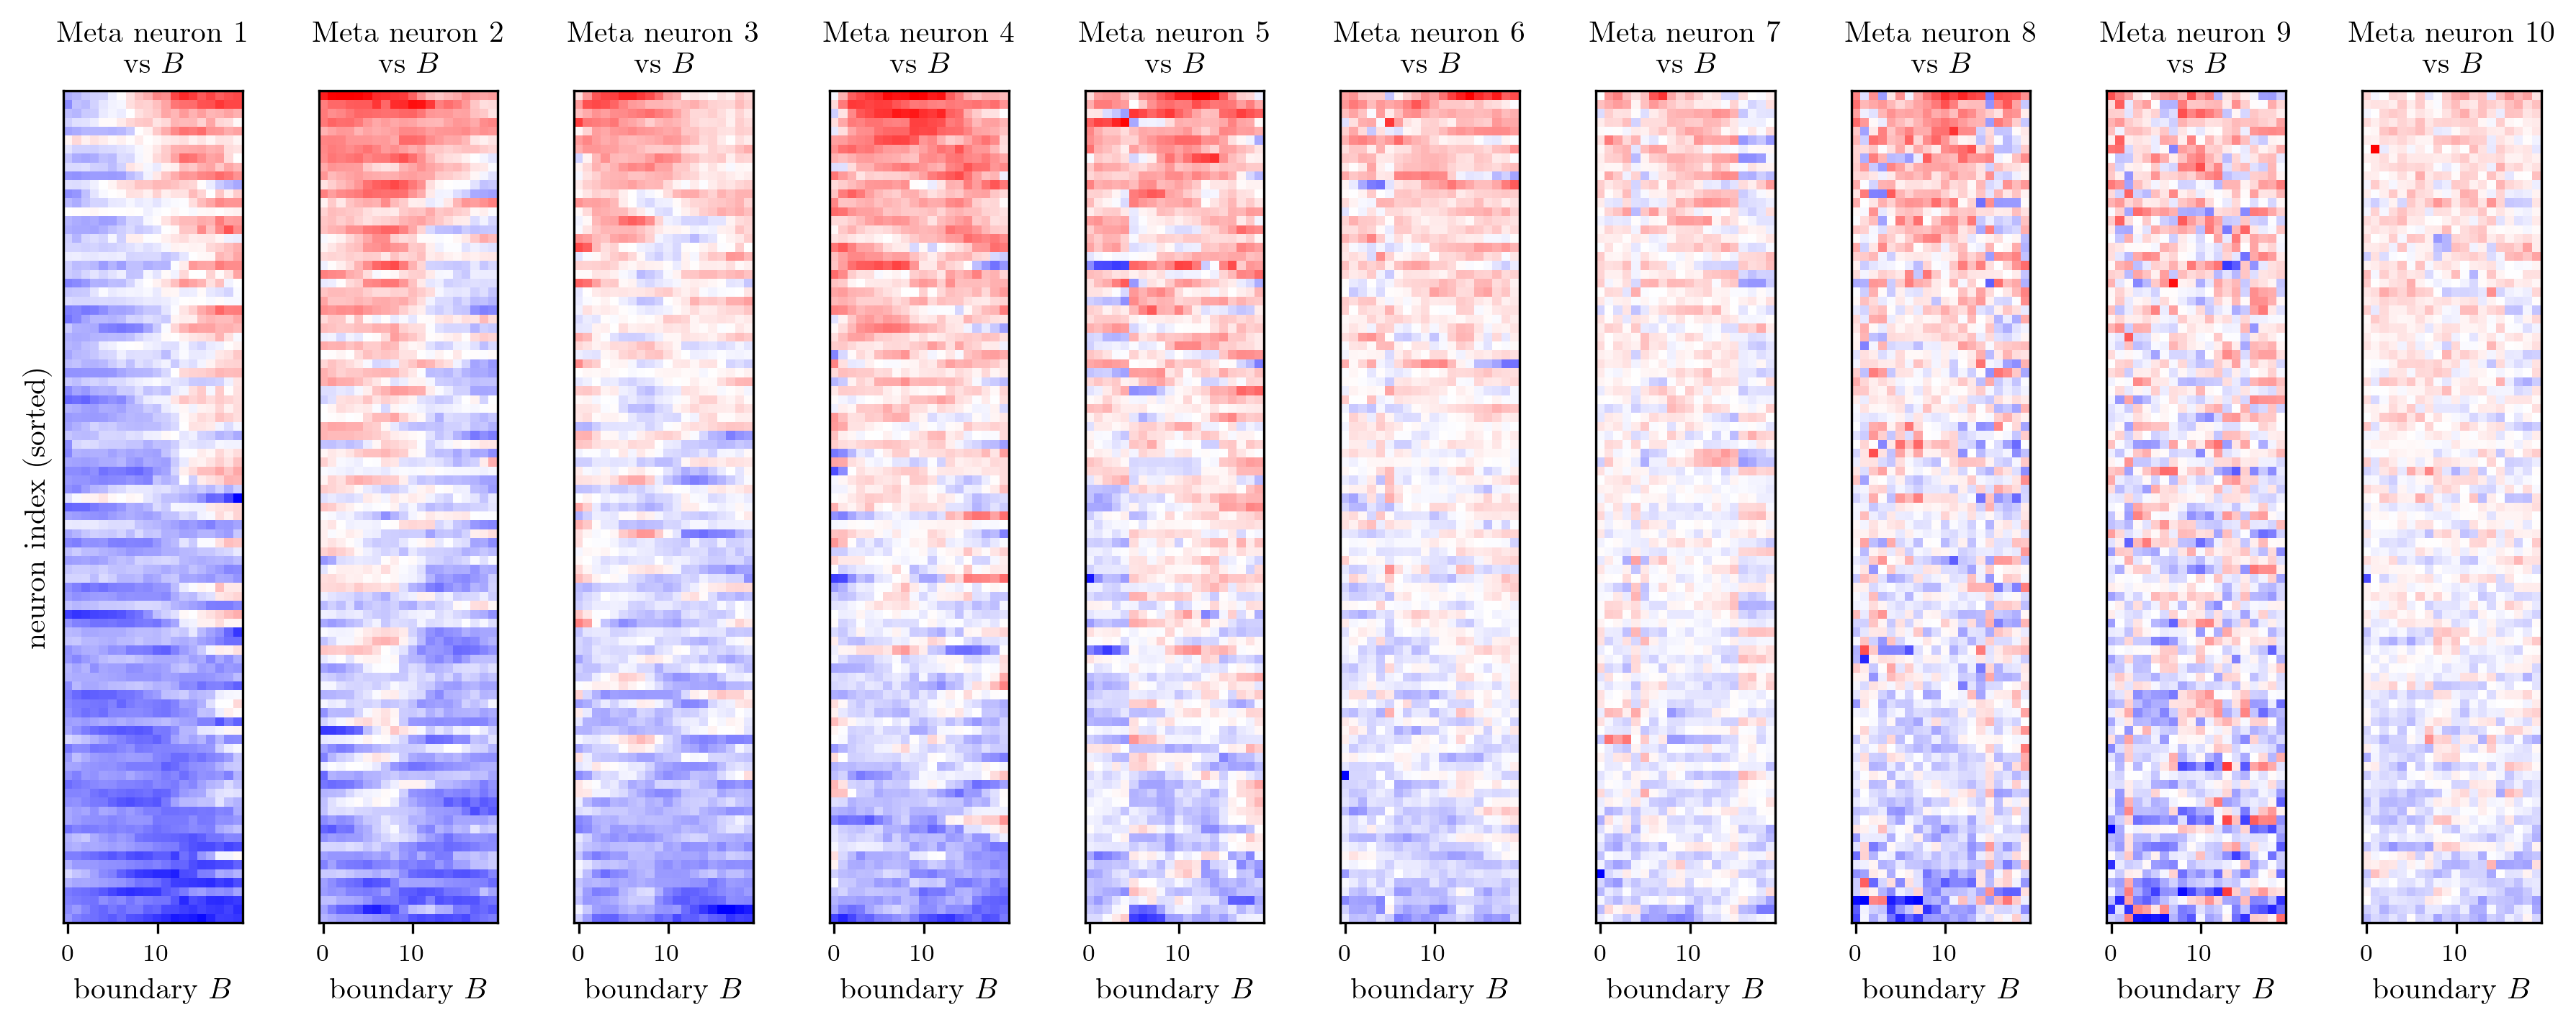

In [8]:
N_modes = 10
fig, ax = plt.subplots(ncols=N_modes, dpi=300, figsize=[15,5])
for n in range(N_modes):
    ax[n] = single_mode_plot(ax[n], n)
